# 07 · Hybrid search and reranking

Vector search finds text with similar *meaning*, but it can miss exact words: product codes, rare
names, the precise term a policy uses ("Advance Saver"). Classic **keyword search** (BM25) is
the opposite: great at exact words, blind to paraphrases. Production systems often use both.

**In this notebook you will:**
- compare BM25 and vector search on exact-term and paraphrase questions,
- fuse the two result lists with **Reciprocal Rank Fusion** (RRF), first by hand,
- re-score the fused candidates with a local **cross-encoder** reranker (no API cost),
- measure all of it against the baseline from notebook 05.

> The reranker needs the optional `[rerank]` extra (`uv sync --extra rerank`, which installs PyTorch,
> a large download). Without it, the rerank cells explain how to install it and skip; everything else runs.

In [1]:
# Setup 1/3: find the project and your API key. Works locally, in Google Colab and in Kaggle.
# (You don't need to read this cell; it is identical in every notebook.)
import importlib.util, os, subprocess, sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
REPO_URL = os.environ.get("RAGLAB_REPO_URL", "")  # set this to the public GitHub URL when running in the cloud


def find_repo_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "pyproject.toml").exists() and (folder / "raglab").is_dir():
            return folder
    return None


ROOT = find_repo_root()
if ROOT is None and (IN_COLAB or IN_KAGGLE):
    if not REPO_URL:
        print("Set REPO_URL (or the RAGLAB_REPO_URL env var) to this project's GitHub URL, then re-run this cell.")
    else:
        ROOT = Path("/content/RAG-lab" if IN_COLAB else "/kaggle/working/RAG-lab")
        if not ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
    try:  # read the key from the platform's secret store
        if IN_COLAB:
            from google.colab import userdata
            os.environ.setdefault("OPENAI_API_KEY", userdata.get("OPENAI_API_KEY") or "")
        else:
            from kaggle_secrets import UserSecretsClient
            os.environ.setdefault("OPENAI_API_KEY", UserSecretsClient().get_secret("OPENAI_API_KEY") or "")
    except Exception:
        print("Add OPENAI_API_KEY to this notebook's secrets (Colab: key icon on the left; Kaggle: Add-ons > Secrets).")

if ROOT is not None and str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from raglab.config import get_settings

settings = get_settings()
if settings.openai_api_key:
    print(f"Project: {ROOT.name if ROOT else '?'} | chat model: {settings.chat_model} | embeddings: {settings.embed_model}")
else:
    print("No OPENAI_API_KEY found. Copy .env.example to .env and paste your key, then restart the kernel.")

Project: RAG-lab | chat model: gpt-6-luna | embeddings: text-embedding-3-small


In [2]:
# Setup 2/3: the baseline index, plus the same chunks for the keyword index
from raglab.bootstrap import ensure_index, get_chunks

store = ensure_index("nb04_baseline")
chunks = get_chunks("nb04_baseline")

[nb04_baseline] reusing index (109 chunks)


In [3]:
# Setup 3/3: start the cost meter at zero
from raglab.llm import cost

cost.reset()

In [4]:
from raglab import retrievers

print("rerank extra installed:", retrievers.has_rerank_extra())

rerank extra installed: True


## 1. BM25: keyword search

**BM25** scores a chunk by how often the question's words appear in it, giving more weight to
rare words and less to long chunks. No embeddings, no API calls: it runs entirely in memory.

In [5]:
vector = retrievers.get_retriever("similarity", store, k=3)
bm25 = retrievers.get_retriever("bm25", store, k=3, chunks=chunks)


def top_sources(retriever, question):
    return [f"{d.metadata['source_file']}: {d.page_content[:60].replace(chr(10), ' ')}" for d in retriever.invoke(question)]


for question in ["What is the Advance Saver rate?", "Can my pet stay with me?"]:
    print(f"Q: {question}")
    print("  vector:", *top_sources(vector, question), sep="\n    ")
    print("  bm25:  ", *top_sources(bm25, question), sep="\n    ")
    print()

Q: What is the Advance Saver rate?
  vector:
    cancellation_policy_2025.md: ## Advance Saver rate   The Advance Saver rate is 15% cheape
    cancellation_policy_2025.md: ## Flexible rate   Guests on the Flexible rate may cancel fr
    loyalty_program.md: ### Silver   Reach Silver after 10 nights in a calendar year
  bm25:  
    cancellation_policy_2025.md: ## Advance Saver rate   The Advance Saver rate is 15% cheape
    cancellation_policy_2024.md: ## Late cancellation and no-shows   If you cancel less than 
    cancellation_policy_2025.md: ## Flexible rate   Guests on the Flexible rate may cancel fr

Q: Can my pet stay with me?
  vector:
    faq.html: Dogs under 10 kg are welcome at Token Lisbon, Token Vancouve
    faq.html: Children under 12 stay free when they share a room with thei
    faq.html: Early check-in depends on availability on the day. To guaran
  bm25:  
    faq.html: Children under 12 stay free when they share a room with thei
    faq.html: Dogs under 10 kg are welcom

Look at where each method finds the answer:

- "Advance Saver" is an exact name, so keyword search finds it immediately. On this small corpus
  vector search finds it too; on a large corpus full of similar policies, exact-term matching
  matters much more.
- "Can my pet stay with me?" never says *dog*. BM25 still surfaces the dog chunk, but only through
  common words ("my", "stay"), and it ranks the children's policy first. Vector search ranks the
  dog chunk first because it understands *pet ≈ dog*.

## 2. Reciprocal Rank Fusion, by hand

How do you merge two ranked lists whose scores aren't comparable (cosine distance vs BM25 score)?
**Ignore the scores and use the ranks.** Each document gets `1 / (60 + rank)` from every list it
appears in, and the sums decide the final order. The constant 60 (from the original paper) stops
the very top rank from dominating.

In [6]:
import pandas as pd

vector_ranking = ["A", "B", "C", "D"]
keyword_ranking = ["C", "E", "A"]
scores = {}
for ranking in (vector_ranking, keyword_ranking):
    for rank, doc in enumerate(ranking, start=1):
        scores[doc] = scores.get(doc, 0) + 1 / (60 + rank)
pd.Series(scores).sort_values(ascending=False).round(5).to_frame("RRF score")

,RRF score
A,0.03227
C,0.03227
B,0.01613
E,0.01613
D,0.01562


**A** and **C** appear in both lists, so they win, even though C was only third for vector search.
Agreement between two different methods is strong evidence. `retrievers.rrf_fuse` does the same
for Documents:

In [7]:
question = "Can my pet stay with me?"
fused = retrievers.rrf_fuse([vector.invoke(question), bm25.invoke(question)], top_n=3)
print(*[d.metadata["source_file"] + ": " + d.page_content[:60].replace("\n", " ") for d in fused], sep="\n")

faq.html: Dogs under 10 kg are welcome at Token Lisbon, Token Vancouve
faq.html: Children under 12 stay free when they share a room with thei
faq.html: Early check-in depends on availability on the day. To guaran


## 3. Hybrid retrieval

The `hybrid` mode takes the top 20 from each method, fuses them with RRF and keeps the best 4:

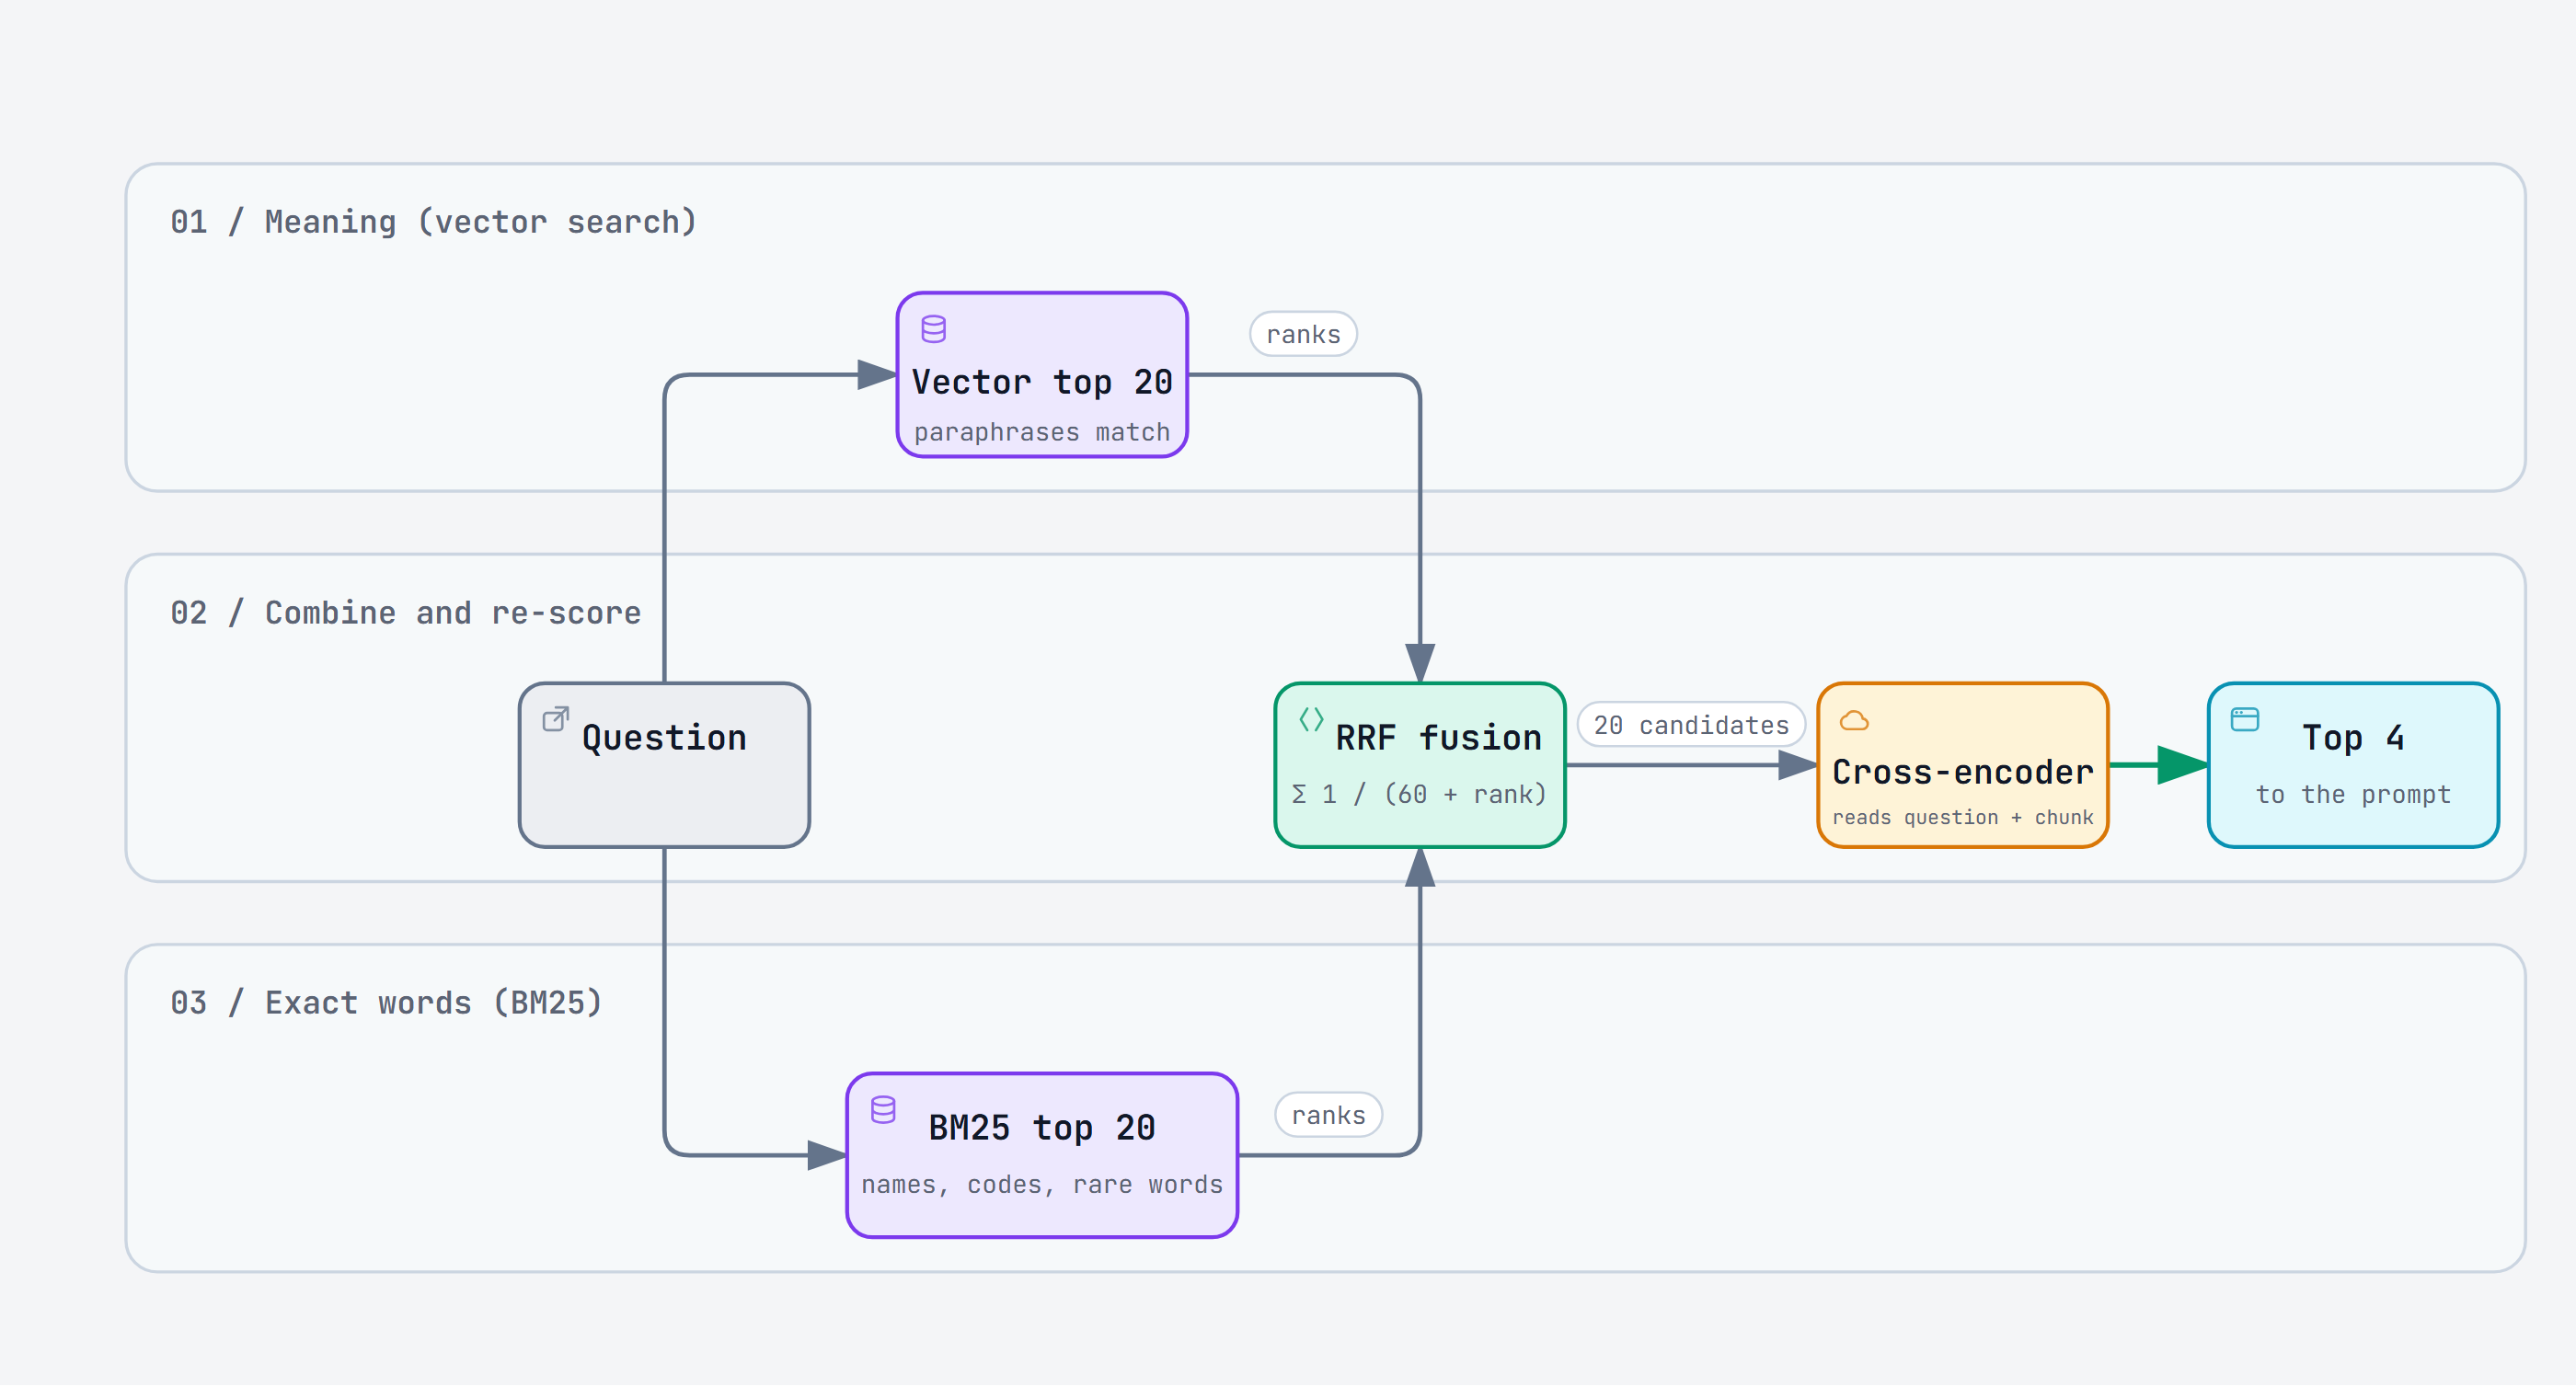

[Open interactive version](../diagrams/hybrid_rerank.html)

In [8]:
from raglab.display import show_diagram

show_diagram("hybrid_rerank")

In [9]:
hybrid = retrievers.get_retriever("hybrid", store, k=4, chunks=chunks)
for question in ["What is the Advance Saver rate?", "Can my pet stay with me?"]:
    print(question, "→", [d.metadata["source_file"] for d in hybrid.invoke(question)])

What is the Advance Saver rate? → ['cancellation_policy_2025.md', 'cancellation_policy_2025.md', 'cancellation_policy_2024.md', 'cancellation_policy_2025.md']
Can my pet stay with me? → ['faq.html', 'faq.html', 'cancellation_policy_2024.md', 'cancellation_policy_2025.md']


## 4. Reranking with a cross-encoder

Embeddings encode the question and each chunk **separately**, then compare the vectors. That's
fast, but coarse. A **cross-encoder** reads the question and a chunk **together** and outputs a
relevance score. It's much more accurate, but far too slow to run over a whole corpus. So we use it
only on the ~20 candidates hybrid search already found: retrieve broadly, then rerank precisely.

We use `cross-encoder/ms-marco-MiniLM-L6-v2`, a small model (about 90 MB) that runs on CPU.
It downloads once on first use.

In [10]:
if retrievers.has_rerank_extra():
    question = "Which hotel has the earliest check-in?"
    candidates = retrievers.get_retriever("hybrid", store, k=20, chunks=chunks).invoke(question)
    reranked = retrievers.rerank(question, candidates, top_n=4)
    print("before rerank:", [d.page_content[:50].replace("\n", " ") for d in candidates[:4]])
    print("after rerank: ", [d.page_content[:50].replace("\n", " ") for d in reranked])
    has_cusco = any("Check-in at Token Cusco" in d.page_content for d in candidates)
    print("Token Cusco's check-in chunk among the 20 candidates:", has_cusco)
else:
    print("Skipping: install the reranker with `uv sync --extra rerank` and restart the kernel.")

before rerank: ['Feature Token Marrakech Rooms 54 Swimming pool Yes', 'Early check-in depends on availability on the day.', 'Token Queenstown — profile  Rooms 210 Swimming poo', 'one way. Feature Token Singapore Location Singapor']
after rerank:  ['Early check-in depends on availability on the day.', 'Token Kyoto — profile  Check-in at Token Kyoto sta', 'one way. Feature Token Singapore Location Singapor', 'Token Vancouver Token Vancouver is a glass tower i']
Token Cusco's check-in chunk among the 20 candidates: True


A reranker can only **reorder** the candidates it is given, and it scores each chunk *on its own*.
In the run saved here, Token Cusco's check-in chunk (the answer) was among the candidates, yet the
reranker preferred a generic "early check-in" FAQ chunk: no single chunk says "earliest", so
per-chunk relevance can't spot it. "Which is earliest?" needs a comparison across *every* hotel,
which structured data handles better (notebook 12 answers it from a table).

## 5. Score everything

BM25, hybrid and the reranker add **no** API cost (BM25 and the cross-encoder run locally),
so we score them on all 35 questions every time.

In [11]:
from raglab import evaluation as ev

items = ev.load_eval("full")
meta = {"profile": "nb04_baseline", "k": 4}
modes = ["similarity", "bm25", "hybrid"] + (["hybrid_rerank"] if retrievers.has_rerank_extra() else [])

retrieval = {}
for mode in modes:
    name = "nb05_baseline_retrieval" if mode == "similarity" else f"nb07_{mode}_retrieval"
    retrieval[mode] = ev.run_or_load(
        name,
        lambda m=mode: ev.retrieval_metrics(retrievers.get_retriever(m, store, k=4, chunks=chunks), items),
        meta={**meta, "retriever": mode},
    )

# Bring in notebook 06's saved results too, when they exist
for mode in ("multiquery", "compression", "selfquery"):
    saved = ev.load_run(f"nb06_{mode}_retrieval")
    if saved is not None:
        retrieval[mode] = saved[0]

ev.compare(retrieval)[["evidence_recall", "hit", "rr", "latency_ms"]]

showing saved full-run results 'nb05_baseline_retrieval' from 2026-11-25 (30 items, cost $0.0000)
showing saved full-run results 'nb07_bm25_retrieval' from 2026-11-25 (30 items, cost $0.0000)
showing saved full-run results 'nb07_hybrid_retrieval' from 2026-11-25 (30 items, cost $0.0000)
showing saved full-run results 'nb07_hybrid_rerank_retrieval' from 2026-11-25 (30 items, cost $0.0000)


,evidence_recall,hit,rr,latency_ms
similarity,0.806,0.667,0.736,1.533
bm25,0.744,0.633,0.647,0.033
hybrid,0.872,0.800,0.772,2.767
hybrid_rerank,0.906,0.867,0.836,364.400
multiquery,0.856,0.767,0.676,3082.567
compression,0.644,0.500,0.669,3036.700
selfquery,0.500,0.467,0.478,1123.500


In [12]:
pd.DataFrame({m: df.groupby("category")["hit"].mean() for m, df in retrieval.items()}).round(2)

,similarity,bm25,hybrid,hybrid_rerank,multiquery,compression,selfquery
category,,,,,,,
comparative,0.20,0.2,0.60,0.80,0.60,0.20,0.20
conflicting_versions,1.00,1.0,1.00,1.00,1.00,1.00,1.00
factual,0.90,1.0,1.00,1.00,0.90,0.70,0.70
metadata_filter,0.40,0.2,0.60,0.60,0.60,0.40,0.00
multi_hop,0.67,0.5,0.67,0.83,0.67,0.17,0.33


## 6. And the answers?

Better retrieval should mean better answers. The quick subset runs live; the full-run table covers all 35.
With only 5 questions, one answer moves accuracy by 20 points, so don't read much into the quick numbers.

In [13]:
from raglab import chains

settings = get_settings()
answer_items = items if settings.full_run else ev.load_eval("quick")
answers = {}
for mode in modes:
    name = "nb05_baseline_answers" if mode == "similarity" else f"nb07_{mode}_answers"
    chain = chains.build_rag_chain_with_sources(retrievers.get_retriever(mode, store, k=4, chunks=chunks))
    answers[mode] = ev.run_or_load(name, lambda c=chain: ev.score_answers(ev.run_rag(c, answer_items)), meta={**meta, "retriever": mode})

pd.DataFrame({m: {"accuracy": df["correct"].mean(), "questions": len(df)} for m, df in answers.items()}).T.round(2)

showing saved full-run results 'nb05_baseline_answers' from 2026-11-25 (35 items, cost $0.0024)
showing saved full-run results 'nb07_bm25_answers' from 2026-11-25 (35 items, cost $0.0024)
showing saved full-run results 'nb07_hybrid_answers' from 2026-11-25 (35 items, cost $0.0025)
showing saved full-run results 'nb07_hybrid_rerank_answers' from 2026-11-25 (35 items, cost $0.0027)


,accuracy,questions
similarity,0.66,35.0
bm25,0.60,35.0
hybrid,0.66,35.0
hybrid_rerank,0.77,35.0


## 7. What the numbers say

In the run saved here:

- **BM25 alone** is *not* better than vector search overall. It wins on exact facts and loses on
  paraphrased and multi-part questions.
- **Hybrid** beats both of its parts. The two methods make *different* mistakes, so their
  combination recovers chunks that either one alone missed, most visibly on comparative and
  metadata-filter questions.
- **Reranking** improves the ranking further at zero API cost: it looks at 20 candidates
  and keeps the 4 that actually answer the question. The price is a model download, some CPU time,
  and latency (look at `latency_ms`).
- **Answers follow, but not one for one.** Hybrid alone retrieves better (hit rate 0.80 vs 0.67)
  yet answers no more questions correctly (66%): it gains a comparative answer and loses a
  multi-hop one, and on metadata-filter questions finding the chunks isn't enough, because the
  model still has to combine several hotels correctly. Hybrid + rerank lifts accuracy to
  77%, the best retrieval setup in the series, with comparative questions going from 40% to 80%.

Compare this with notebook 06: the LLM-powered retrievers spent API calls for a small gain
(MultiQuery) or a loss (compression, SelfQuery), while two classic information-retrieval
techniques did better for free. **Try the cheap, well-understood
tools before the clever ones.**

## Your turn

1. Change `fetch_k` (the number of candidates per method, default 20) to 5 and to 50 for
   `hybrid_rerank`. How do quality and latency move?
2. In `rrf_fuse`, try `k_rrf=1` instead of 60. On the toy example in section 2, what happens to C?
3. Find a question where BM25 alone beats hybrid. Why does fusion lose there?

## Key takeaways

- Vector search matches meaning; BM25 matches exact words. They fail differently, so combine them.
- RRF merges ranked lists using ranks only: simple, robust, no score calibration needed.
- A cross-encoder reranker re-scores a short candidate list with high accuracy, locally and for free.
- "Retrieve broadly, then rerank precisely" is one of the most reliable upgrades for a RAG system.

**Added to raglab:** `retrievers.rrf_fuse / rerank / has_rerank_extra / tokenize / HybridRetriever /
RERANK_MODEL`, and `get_retriever` modes `bm25`, `hybrid`, `hybrid_rerank`.

In [14]:
cost.report()

Cost: no API calls in this notebook ($0.0000)
